In [ ]:
# helper functions


In [145]:
# This notebook tests subregion based scenario generation as described in Larsen, Madsen and Solomon (2004)

# Ignore Idle Points for now

# Do it according to the paper with rejection if the sum of the subregions does not equal the total number of points

import numpy as np

N_SUBREG = 9

N_TOT = 39 # Total number of customers - Depot

ARRIVAL_WEIGHT_1 = [1,2,1,2,4,2,1,2,1]

ARRIVAL_WEIGHT_2 = [5,1,1,10,6,3,1,15,12]

DEPOT_LOCATION = np.array([0.5, 0.5])

TIME_HORIZON = 480

L = 60

TW_MIN = 60
TW_MAX = 180

SPEED = 4 / 60

n_imm_subreg = np.zeros(N_SUBREG)

REACTION_TIME = 60

while np.sum(n_imm_subreg) != N_TOT:
    y_ix = -1 # Start at -1 so that the first increment is 0

    n_imm_subreg = np.zeros(N_SUBREG)

    customer_locations = []

    arrival_times = []

    service_times = []
    start_times = []
    end_times = []

    for j in range(N_SUBREG):
        exp_n_imm = ARRIVAL_WEIGHT_1[j]/np.sum(ARRIVAL_WEIGHT_1) * N_TOT
        arrival_rate = exp_n_imm / TIME_HORIZON

        # Sample the poisson distribution
        n_imm = np.random.poisson(lam=arrival_rate*TIME_HORIZON, size=1)
        n_imm_subreg[j] = n_imm.item()

        # Generate arrival times for these customers
        arrival_times.append(np.random.uniform(0, TIME_HORIZON, n_imm))

        # Generate customer locations according to their subregion
        if j % np.sqrt(N_SUBREG) == 0:
            y_ix += 1
            if y_ix % 2 == 0:
                x_ix = -1
            else:
                x_ix = int(np.sqrt(N_SUBREG))

        if y_ix % 2 == 0:
            x_ix += 1
        else:
            x_ix -= 1

        x_limit_1 = x_ix / np.sqrt(N_SUBREG)
        x_limit_2 = (x_ix+1) / np.sqrt(N_SUBREG)
        x_coords = np.random.uniform(x_limit_1, x_limit_2, n_imm)
        
        y_limit_1 = y_ix / np.sqrt(N_SUBREG)
        y_limit_2 = (y_ix+1) / np.sqrt(N_SUBREG)
        y_coords = np.random.uniform(y_limit_1, y_limit_2, n_imm)

        customer_locations.append(np.column_stack((x_coords, y_coords)))

        # Generate customer service times
        service_times.append(np.random.lognormal(0.8777, 0.6647, n_imm))

        # Generate customer time windows
        earliest_times = np.linalg.norm(customer_locations[j] - DEPOT_LOCATION, axis=1) / SPEED
        start_times.append(np.maximum(earliest_times, arrival_times[j] + REACTION_TIME))
        end_times.append(np.array([np.random.uniform(start_times[j][i] + TW_MIN, np.min([start_times[j][i] + TW_MAX, TIME_HORIZON + L + REACTION_TIME])) for i in range(n_imm.item())]))
        


all_customers = np.concatenate(customer_locations)
all_arrival_times = np.concatenate(arrival_times)
all_service_times = np.concatenate(service_times)
all_start_times = np.concatenate(start_times)
all_end_times = np.concatenate(end_times)

# Prepend the depot to each array
all_customers = np.vstack((DEPOT_LOCATION, all_customers))
all_arrival_times = np.concatenate(([0], all_arrival_times))
all_service_times = np.concatenate(([0], all_service_times))
all_start_times = np.concatenate(([0], all_start_times))
all_end_times = np.concatenate(([0], all_end_times))

In [146]:
# Now the advance request customers

MAX_DOD = 0.8
MIN_DOD = 0.2

n_adv = np.random.randint(np.ceil(N_TOT*MIN_DOD), np.floor(N_TOT*MAX_DOD))

# choose indices of advance request customers at random
adv_ix = np.random.choice(range(1, N_TOT), n_adv, replace=False)

# set arrival times of advance request customers to be 0
all_arrival_times[adv_ix] = 0

# Regenerate time windows for advance request customers
earliest_times = np.linalg.norm(all_customers[adv_ix] - DEPOT_LOCATION, axis=1) / SPEED
adv_start_times = np.maximum(earliest_times, np.random.uniform(0, TIME_HORIZON + L - TW_MIN, n_adv))
adv_end_times = np.array([np.random.uniform(adv_start_times[i] + TW_MIN, np.min([adv_start_times[i] + TW_MAX, TIME_HORIZON + L])) for i in range(n_adv)])

# update the start and end time arrays
all_start_times[adv_ix] = adv_start_times
all_end_times[adv_ix] = adv_end_times

In [147]:
# sort everything by arrival time
sorted_ix = np.argsort(all_arrival_times)
all_customers = all_customers[sorted_ix]
all_arrival_times = all_arrival_times[sorted_ix]
all_service_times = all_service_times[sorted_ix]
all_start_times = all_start_times[sorted_ix]
all_end_times = all_end_times[sorted_ix]

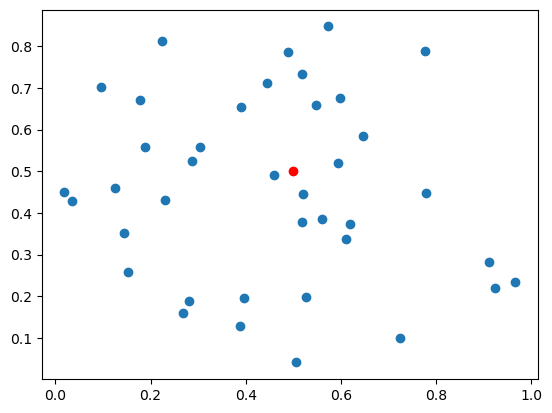

In [126]:
# plot customer locations
import matplotlib.pyplot as plt

plt.scatter(all_customers[1:,0], all_customers[1:,1])
plt.scatter(all_customers[0,0], all_customers[0,1], c='r')
plt.show()

In [2]:
from problems.problem_pdtrptw import PDTRPTWDataset
from torch.utils.data import DataLoader
from tqdm import tqdm
from problems.state_pdtrptw import StatePDTRPTW
import numpy as np
import torch

# set random seed for reproducibility
np.random.seed(0)
torch.manual_seed(0)

dataset = PDTRPTWDataset(min_total=40, max_total=40, min_dod=0.2, max_dod=0.8, time_horizon=480, service_times_mu=0.8777, service_times_sigma=0.6647, batch_size=16, num_samples=1280, neighbors=20, knn_strat='percentage')

100%|##########| 80/80 [00:22<00:00,  3.52it/s]


In [3]:
dataloader = DataLoader(dataset, batch_size=16, shuffle=False, num_workers=1)

In [4]:
batch_size = 16
all_selections = []

for batch in dataloader:
    all_nodes = batch['all_nodes']
    service_times = batch['service_times']
    arrival_times = batch['arrival_times']
    window_starts = batch['window_starts']
    window_ends = batch['window_ends']
    input = {
        'loc': all_nodes,
        'service_times': service_times,
        'arrival_times': arrival_times,
        'window_starts': window_starts,
        'window_ends': window_ends
    }
    ids = torch.arange(batch_size, dtype=torch.int64)[:, None]
    selected = torch.zeros((batch_size, 1), dtype = torch.int64)
    state = StatePDTRPTW.initialize(input)
    while not state.all_finished():
        mask = state.get_mask()
        distances_to_current = (all_nodes - all_nodes[ids, selected]).norm(p=2, dim=-1)

        distances_to_current[mask[:,0,:]] = float('inf')

        selected = torch.argmin(distances_to_current, dim=1)
        # probs = torch.ones((batch_size, all_nodes.size(1)))
        # probs[mask[:,0,:]] = 0
        # probs = probs / probs.sum()
        # selected = torch.multinomial(probs, 1).squeeze(1)
        state = state.update(selected)

        all_selections.append(selected)

        selected = selected[:, None]

    break 


In [49]:
# solve problem with a heuristic which selects the node with the soonest time window

# From the state, we will need the following information:
# - current time
# - end of time window for the unvisited customers 


batch_size = 16
all_selections = []

for batch in dataloader:
    all_nodes = batch['all_nodes']
    service_times = batch['service_times']
    arrival_times = batch['arrival_times']
    window_starts = batch['window_starts']
    window_ends = batch['window_ends']
    input = {
        'loc': all_nodes,
        'service_times': service_times,
        'arrival_times': arrival_times,
        'window_starts': window_starts,
        'window_ends': window_ends
    }
    ids = torch.arange(batch_size, dtype=torch.int64)[:, None]
    selected = torch.zeros((batch_size, 1), dtype = torch.int64)
    state = StatePDTRPTW.initialize(input)
    while not state.all_finished():
        mask = state.get_mask()
        
        current_times = state.cur_times

        time_to_end = window_ends - current_times

        time_to_end[mask[:,0,:]] = float('inf')

        selected = torch.argmin(time_to_end, dim=1)
        # probs = torch.ones((batch_size, all_nodes.size(1)))
        # probs[mask[:,0,:]] = 0
        # probs = probs / probs.sum()
        # selected = torch.multinomial(probs, 1).squeeze(1)
        state = state.update(selected)

        all_selections.append(selected)

        selected = selected[:, None]

    break 

In [45]:
import numpy as np

# function for calculating the cost of a solution

# Gamma and Theta chosen with goal of minimizing an equally weighted combination of the distance travelled and lateness
TIME_HORIZON = 480
L = 60
GAMMA = 1
THETA = 3

# Gamma and Theta chosen witht the goal of minimizing lateness
# GAMMA = 1000
# THETA = 1

def get_cost(all_coords, solution, visit_times, end_times):
    # solution is a list of customers in the order that they were visited.
    # visit_times is a list of the times at which each customer was visited.
    # end_times is a list of the end of the time window for each customer.

    # calculate the distance travelled as for pdtrp

    # gather coordinates of customers in the order they were visited

    d = all_coords[solution]

    distance = np.linalg.norm(d[1:] - d[:-1], axis=1)

    print(np.sum(distance))

    # To calculate the penalty for lateness, we need to calculate the difference between the visit time and the end of the time window for every customer

    time_diff = np.maximum(0, visit_times - end_times) / (TIME_HORIZON + L)

    print(np.sum(time_diff))

    # calculate the cost

    return THETA * np.sum(distance) + GAMMA * np.sum(time_diff)

In [53]:
get_cost(all_nodes[0], all_selections[0].squeeze().numpy(), state.visit_times[0].squeeze().numpy(), window_ends[0].squeeze().numpy())

5.1092863
0.0


15.327858924865723

In [4]:
from problems.problem_pdtrptw import PDTRPTWDataset
from torch.utils.data import DataLoader
from tqdm import tqdm
from problems.state_pdtrptw import StatePDTRPTW
import torch
import numpy as np

# Generate validation sets for the PDTRPTW problem. We'll use a solution which prioritizes the customers with the soonest time windows as a baseline

# Generate validation sets according to Larsen, Madsen and Solomon (2004)

filename = 'valsetN1.txt'
N_SAMPLES = 1280
BATCH_SIZE = 1
N_TOTAL = 40

# 1 arrival weights
arrival_weights = [1,2,1,2,4,2,1,2,1]
# 2 arrival weights
#arrival_weights = [5,1,1,10,6,3,1,15,12]
# N time window constraints
TW_MIN=30/480
TW_MAX=90/480
# W time window constraints
#TW_MIN=60/480
#TW_MAX=180/480

# set random seed for reproducibility
np.random.seed(12345)
torch.manual_seed(12345)

dataset = PDTRPTWDataset(min_total=N_TOTAL, max_total=N_TOTAL, min_dod=0.2, max_dod=0.8, time_horizon=1, service_times_mu=0.8777, service_times_sigma=0.6647, batch_size=1, num_samples=1280, neighbors=20, knn_strat='percentage', arrival_weights=arrival_weights, tw_min=TW_MIN, tw_max=TW_MAX)

dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=1)

all_nodes_list = []
arrival_times_list = []
service_times_list = []
window_start_list = []
window_end_list = []
tours_list = []
visit_times_list = []

for batch in tqdm(dataloader):
    all_nodes = batch['all_nodes']
    service_times = batch['service_times']
    arrival_times = batch['arrival_times']
    window_starts = batch['window_starts']
    window_ends = batch['window_ends']
    input = {
        'loc': all_nodes,
        'service_times': service_times,
        'arrival_times': arrival_times,
        'window_starts': window_starts,
        'window_ends': window_ends
    }
    ids = torch.arange(BATCH_SIZE, dtype=torch.int64)[:, None]
    all_selected = []
    selected = torch.zeros((BATCH_SIZE, 1), dtype = torch.int64)
    all_selected.append(selected.item())
    state = StatePDTRPTW.initialize(input)
    while not state.all_finished():
        mask = state.get_mask()
        # print("visited_:")
        # print(state.visited_)
        # print("not_arrived_:")
        # print(state.not_arrived_)
        # print("mask:")
        # print(mask)
        
        current_times = state.cur_times

        time_to_end = window_ends - current_times

        time_to_end[mask[:,0,:]] = float('inf')

        selected = torch.argmin(time_to_end, dim=1)
        state = state.update(selected)

        all_selected.append(selected.item())

        selected = selected[:, None]


    all_nodes_list += list(all_nodes.numpy())
    arrival_times_list += list(arrival_times.numpy())
    service_times_list += list(service_times.numpy())
    window_start_list += list(window_starts.numpy())
    window_end_list += list(window_ends.numpy())
    tours_list += [all_selected]
    visit_times_list += [state.visit_times[0][0].numpy()]

with open("data/pdtrptw/" + filename, "w") as f:
    for i in range(N_SAMPLES):
        f.write( " ".join( str(x)+str(" ")+str(y) for x,y in all_nodes_list[i]))
        f.write( str(" ") + str("arrival_times" + str(" ")))
        f.write( str(" ").join(str(x) for x in arrival_times_list[i]))
        f.write( str(" ") + str("service_times" + str(" ")))
        f.write( str(" ").join(str(x) for x in service_times_list[i]))
        f.write( str(" ") + str("window_starts" + str(" ")))
        f.write( str(" ").join(str(x) for x in window_start_list[i]))
        f.write( str(" ") + str("window_ends" + str(" ")))
        f.write( str(" ").join(str(x) for x in window_end_list[i]))
        f.write( str(" ") + str('tour' + str(" ")))
        f.write( str(" ").join(str(node_idx+1) for node_idx in tours_list[i]))
        f.write( str(" ") + str(tours_list[i][0]+1))            
        f.write( str(" ") + str('visit_times' + str(" ")))
        f.write( str(" ").join(str(x) for x in visit_times_list[i]))
        f.write( "\n" )

100%|██████████| 1280/1280 [00:20<00:00, 63.66it/s]


In [3]:
tours_list

[[0,
  12,
  11,
  15,
  14,
  4,
  17,
  13,
  10,
  16,
  18,
  20,
  6,
  9,
  21,
  22,
  19,
  24,
  23,
  7,
  25,
  26,
  5,
  28,
  27,
  1,
  29,
  2,
  30,
  31,
  32,
  33,
  3,
  34,
  35,
  8,
  36,
  39,
  37,
  38],
 [0,
  21,
  2,
  6,
  14,
  23,
  20,
  5,
  22,
  17,
  24,
  25,
  16,
  26,
  27,
  19,
  29,
  28,
  1,
  3,
  12,
  15,
  18,
  10,
  30,
  33,
  31,
  32,
  34,
  35,
  13,
  37,
  4,
  8,
  36,
  9,
  11,
  7,
  38,
  39],
 [0,
  22,
  12,
  17,
  23,
  28,
  1,
  4,
  31,
  30,
  29,
  5,
  9,
  20,
  24,
  32,
  33,
  2,
  34,
  11,
  16,
  26,
  14,
  8,
  35,
  21,
  15,
  10,
  7,
  36,
  25,
  18,
  6,
  27,
  37,
  19,
  38,
  13,
  3,
  39]]